In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)

In [2]:
columns = [
    "CheckingAccount",
    "Duration",
    "CreditHistory",
    "Purpose",
    "CreditAmount",
    "Savings",
    "Employment",
    "InstallmentRate",
    "PersonalStatusSex",
    "OtherDebtors",
    "ResidenceSince",
    "Property",
    "Age",
    "OtherInstallmentPlans",
    "Housing",
    "ExistingCredits",
    "Job",
    "Dependents",
    "Telephone",
    "ForeignWorker",
    "Target"
]

df = pd.read_csv(
    "german.data",
    sep=r"\s+",
    header=None
)

assert df.shape[1] == len(columns)

df.columns = columns

# Original labels: 1 = good, 2 = bad
assert set(df["Target"].unique()) == {1, 2}

# New labels: 0 = good, 1 = bad
df["Target"] = df["Target"].map({1: 0, 2: 1})

display(df.head())
print("Dataset shape:", df.shape)

,CheckingAccount,Duration,CreditHistory,Purpose,CreditAmount,Savings,Employment,InstallmentRate,PersonalStatusSex,OtherDebtors,ResidenceSince,Property,Age,OtherInstallmentPlans,Housing,ExistingCredits,Job,Dependents,Telephone,ForeignWorker,Target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,1


Dataset shape: (1000, 21)


In [3]:
numeric_features = [
    "Duration",
    "CreditAmount",
    "InstallmentRate",
    "ResidenceSince",
    "Age",
    "ExistingCredits",
    "Dependents"
]

categorical_features = [
    column for column in df.columns
    if column not in numeric_features + ["Target"]
]

quality_table = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing values": df.isna().sum(),
    "Unique values": df.nunique()
})

display(quality_table)

print("Duplicate rows:", df.duplicated().sum())
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

for column in categorical_features:
    print(column, ":", sorted(df[column].unique()))

,Data type,Missing values,Unique values
CheckingAccount,object,0,4
Duration,int64,0,33
CreditHistory,object,0,5
Purpose,object,0,10
CreditAmount,int64,0,921
Savings,object,0,5
Employment,object,0,5
InstallmentRate,int64,0,4
PersonalStatusSex,object,0,4
OtherDebtors,object,0,3


Duplicate rows: 0
Numerical features: 7
Categorical features: 13
CheckingAccount : ['A11', 'A12', 'A13', 'A14']
CreditHistory : ['A30', 'A31', 'A32', 'A33', 'A34']
Purpose : ['A40', 'A41', 'A410', 'A42', 'A43', 'A44', 'A45', 'A46', 'A48', 'A49']
Savings : ['A61', 'A62', 'A63', 'A64', 'A65']
Employment : ['A71', 'A72', 'A73', 'A74', 'A75']
PersonalStatusSex : ['A91', 'A92', 'A93', 'A94']
OtherDebtors : ['A101', 'A102', 'A103']
Property : ['A121', 'A122', 'A123', 'A124']
OtherInstallmentPlans : ['A141', 'A142', 'A143']
Housing : ['A151', 'A152', 'A153']
Job : ['A171', 'A172', 'A173', 'A174']
Telephone : ['A191', 'A192']
ForeignWorker : ['A201', 'A202']


In [4]:
class_summary = (
    df["Target"]
    .value_counts()
    .sort_index()
    .rename("Count")
    .to_frame()
)

class_summary.index.name = "Target"
class_summary["Class"] = ["Good credit", "Bad credit"]
class_summary["Percentage"] = (
    class_summary["Count"] / len(df) * 100
)

display(class_summary)

imbalance_ratio = (
    class_summary.loc[0, "Count"]
    / class_summary.loc[1, "Count"]
)

print("Good / Bad ratio:", round(imbalance_ratio, 2))
print("Majority baseline accuracy:",
      round(class_summary.loc[0, "Count"] / len(df), 4))

,Count,Class,Percentage
Target,,,
0,700,Good credit,70.0
1,300,Bad credit,30.0


Good / Bad ratio: 2.33
Majority baseline accuracy: 0.7


این دیتاست شامل ۱۰۰۰ مشتریه که ۷۰ درصدشون خوش‌حساب و ۳۰ درصدشون بدحساب هستن. بنابراین اگر مدلی همه مشتری‌ها رو خوش‌حساب پیش‌بینی کنه، به دقت ۷۰ درصد می‌رسه، ولی هیچ مشتری بدحسابی رو شناسایی نمی‌کنه. پس برای ارزیابی باید علاوه بر دقت، توانایی تشخیص بدحساب‌ها و هزینه خطاها رو هم بررسی کنیم.

In [5]:
X = df.drop(columns="Target")
y = df["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Use training rows for exploratory analysis
train_df = X_train.copy()
train_df["Target"] = y_train

split_summary = pd.DataFrame({
    "Subset": ["Train", "Test"],
    "Rows": [len(X_train), len(X_test)],
    "Good credit": [(y_train == 0).sum(), (y_test == 0).sum()],
    "Bad credit": [(y_train == 1).sum(), (y_test == 1).sum()],
    "Bad credit rate": [y_train.mean(), y_test.mean()]
})

display(split_summary)

,Subset,Rows,Good credit,Bad credit,Bad credit rate
0,Train,800,560,240,0.3
1,Test,200,140,60,0.3


In [6]:
display(X_train[numeric_features].describe().round(2))

outlier_rows = []

for column in ["CreditAmount", "Duration", "Age"]:
    q1 = X_train[column].quantile(0.25)
    q3 = X_train[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (X_train[column] < lower_bound)
        | (X_train[column] > upper_bound)
    )

    outlier_rows.append({
        "Feature": column,
        "Lower bound": lower_bound,
        "Upper bound": upper_bound,
        "Outlier count": outliers.sum(),
        "Outlier percentage": outliers.mean() * 100
    })

outlier_table = pd.DataFrame(outlier_rows)
display(outlier_table.round(2))

,Duration,CreditAmount,InstallmentRate,ResidenceSince,Age,ExistingCredits,Dependents
count,800.00,800.00,800.00,800.00,800.00,800.00,800.00
mean,20.77,3189.59,2.94,2.83,35.32,1.41,1.16
std,11.82,2673.55,1.12,1.11,11.05,0.57,0.37
min,4.00,276.00,1.00,1.00,19.00,1.00,1.00
25%,12.00,1353.00,2.00,2.00,27.00,1.00,1.00
50%,18.00,2317.00,3.00,3.00,33.00,1.00,1.00
75%,24.00,3933.00,4.00,4.00,41.00,2.00,1.00
max,60.00,15945.00,4.00,4.00,75.00,4.00,2.00


,Feature,Lower bound,Upper bound,Outlier count,Outlier percentage
0,CreditAmount,-2517.0,7803.0,58,7.25
1,Duration,-6.0,42.0,50,6.25
2,Age,6.0,62.0,25,3.12


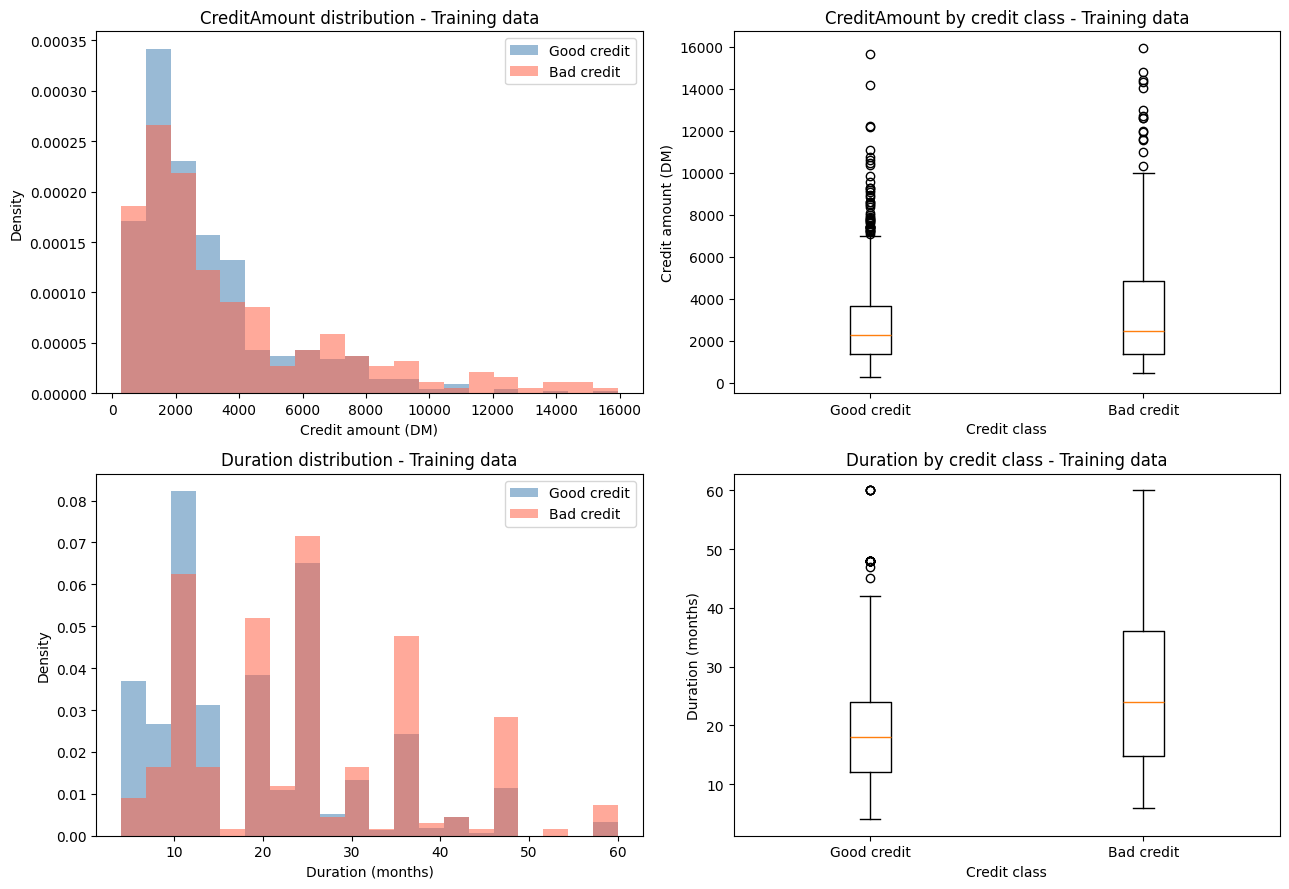

In [7]:
plot_columns = ["CreditAmount", "Duration"]
plot_labels = ["Credit amount (DM)", "Duration (months)"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for i, column in enumerate(plot_columns):
    good_values = train_df.loc[
        train_df["Target"] == 0, column
    ]

    bad_values = train_df.loc[
        train_df["Target"] == 1, column
    ]

    bins = np.histogram_bin_edges(
        train_df[column],
        bins=20
    )

    axes[i, 0].hist(
        good_values,
        bins=bins,
        density=True,
        alpha=0.55,
        label="Good credit",
        color="steelblue"
    )

    axes[i, 0].hist(
        bad_values,
        bins=bins,
        density=True,
        alpha=0.55,
        label="Bad credit",
        color="tomato"
    )

    axes[i, 0].set_title(
        f"{column} distribution - Training data"
    )
    axes[i, 0].set_xlabel(plot_labels[i])
    axes[i, 0].set_ylabel("Density")
    axes[i, 0].legend()

    axes[i, 1].boxplot([good_values, bad_values])
    axes[i, 1].set_xticks([1, 2])
    axes[i, 1].set_xticklabels(["Good credit", "Bad credit"])
    axes[i, 1].set_title(
        f"{column} by credit class - Training data"
    )
    axes[i, 1].set_xlabel("Credit class")
    axes[i, 1].set_ylabel(plot_labels[i])

plt.tight_layout()
plt.show()

توزیع مبلغ وام راست‌چوله است؛ یعنی بیشتر مشتری‌ها وام‌های کوچک‌تر گرفتن و تعداد کمی وام‌های خیلی بزرگ دارن. در گروه بدحساب‌ها، میانه مدت بازپرداخت حدود ۲۴ ماهه، در حالی که برای خوش‌حساب‌ها حدود ۱۸ ماهه. طبق روش فاصله بین چارکی، ۷٫۲۵ درصد مبلغ وام‌ها، ۶٫۲۵ درصد مدت وام‌ها و ۳٫۱۲ درصد سن‌ها خارج از محدوده معمول قرار گرفتن؛ اما چون مدرکی برای اشتباه بودن این مقادیر نداریم، فعلاً نگهشون می‌داریم.

,Customers,Bad customers,Bad credit rate,Bad credit rate (%),Description
CheckingAccount,,,,,
A14,316,38,0.12,12.03,No checking account
A13,51,13,0.25,25.49,Balance >= 200 DM / salary assignment
A12,214,84,0.39,39.25,Balance 0-199 DM
A11,219,105,0.48,47.95,Balance < 0 DM


,Customers,Bad customers,Bad credit rate,Bad credit rate (%),Description
CreditHistory,,,,,
A34,240,42,0.18,17.50,Critical account / credits elsewhere
A33,72,23,0.32,31.94,Past payment delays
A32,416,134,0.32,32.21,Existing credits paid duly so far
A31,41,22,0.54,53.66,All credits at this bank paid duly
A30,31,19,0.61,61.29,No credit / all paid duly


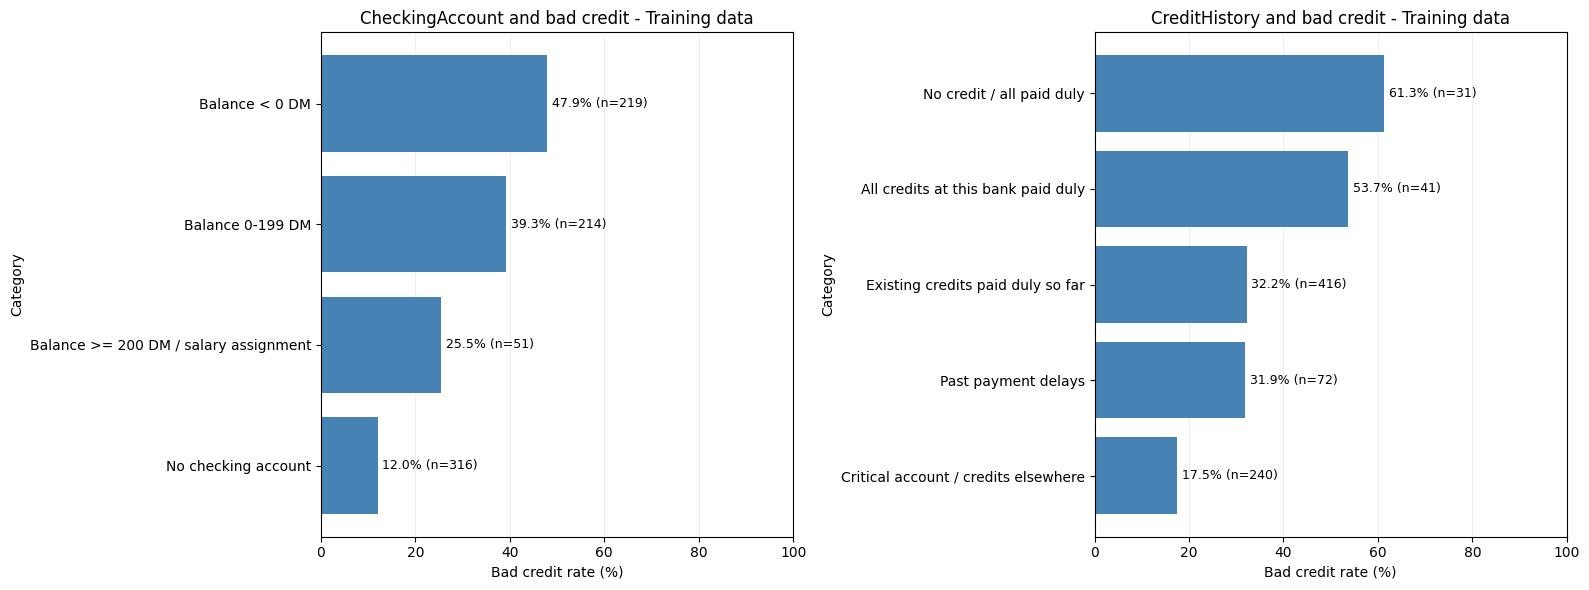

In [8]:
checking_labels = {
    "A11": "Balance < 0 DM",
    "A12": "Balance 0-199 DM",
    "A13": "Balance >= 200 DM / salary assignment",
    "A14": "No checking account"
}

history_labels = {
    "A30": "No credit / all paid duly",
    "A31": "All credits at this bank paid duly",
    "A32": "Existing credits paid duly so far",
    "A33": "Past payment delays",
    "A34": "Critical account / credits elsewhere"
}

category_tables = {}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, column, labels in zip(
    axes,
    ["CheckingAccount", "CreditHistory"],
    [checking_labels, history_labels]
):
    table = (
        train_df.groupby(column)["Target"]
        .agg(["count", "sum", "mean"])
        .rename(columns={
            "count": "Customers",
            "sum": "Bad customers",
            "mean": "Bad credit rate"
        })
    )

    table["Bad credit rate (%)"] = (
        table["Bad credit rate"] * 100
    )

    table["Description"] = table.index.map(labels)

    table = table.sort_values("Bad credit rate (%)")
    category_tables[column] = table

    display(table.round(2))

    bars = ax.barh(
        table["Description"],
        table["Bad credit rate (%)"],
        color="steelblue"
    )

    for bar, rate, count in zip(
        bars,
        table["Bad credit rate (%)"],
        table["Customers"]
    ):
        ax.text(
            rate + 1,
            bar.get_y() + bar.get_height() / 2,
            f"{rate:.1f}% (n={count})",
            va="center",
            fontsize=9
        )

    ax.set_xlim(0, 100)
    ax.set_title(f"{column} and bad credit - Training data")
    ax.set_xlabel("Bad credit rate (%)")
    ax.set_ylabel("Category")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

وضعیت حساب جاری در این نمونه ارتباط قابل‌توجهی با بدحسابی داره؛ نرخ بدحسابی برای مشتری‌های دارای مانده منفی حدود ۴۸ درصد و برای گروه بدون حساب جاری حدود ۱۲ درصده. در سابقه اعتباری هم تفاوت دیده می‌شه، ولی بعضی گروه‌ها فقط ۳۱ یا ۴۱ مشتری دارن و نرخ‌هاشون باید با احتیاط تفسیر بشه. این نتایج الگوی همین داده‌ها هستن و ثابت نمی‌کنن که مثلاً نداشتن حساب جاری باعث کاهش ریسک می‌شه.

بر اساس بررسی اولیه، وضعیت حساب جاری، سابقه اعتباری و مدت وام سه گزینه مهم برای تفکیک مشتری‌های خوش‌حساب و بدحساب هستن. دو ویژگی اول اختلاف قابل‌توجهی در نرخ بدحسابی گروه‌ها نشون دادن و مدت وام هم بین ویژگی‌های عددی بیشترین همبستگی مثبت با بدحسابی رو داشت، هرچند این همبستگی نسبتاً ضعیفه. این انتخاب اولیه است و اهمیت این ویژگی‌ها رو بعداً با مدل و تحلیل توضیح‌پذیری بررسی می‌کنیم.

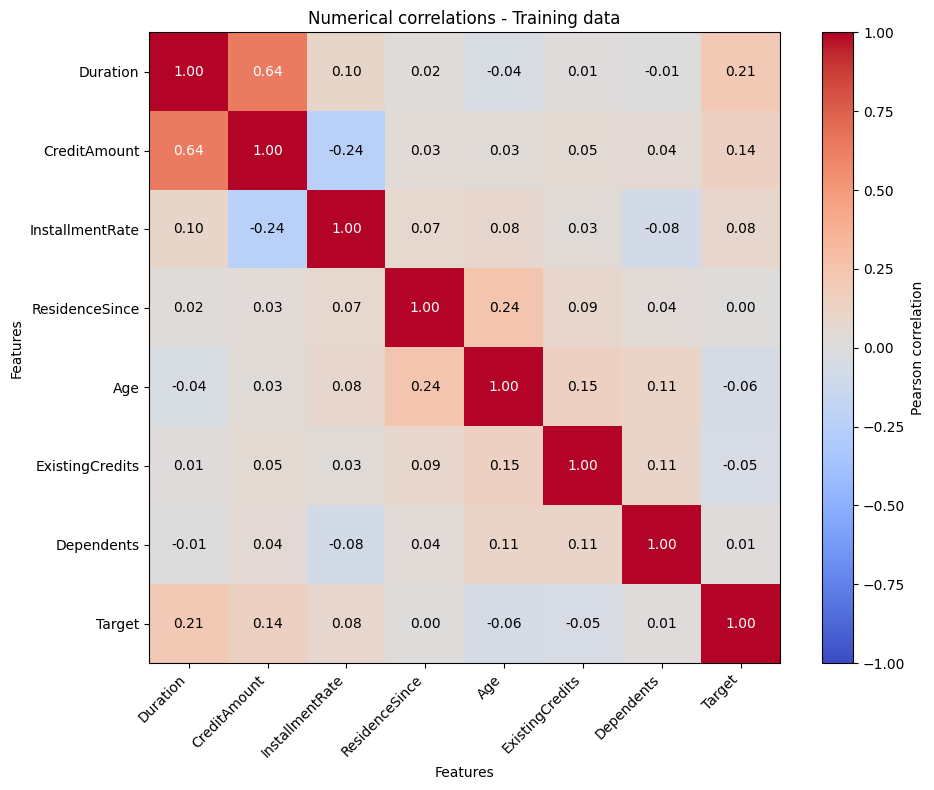

Duration           0.206
CreditAmount       0.139
InstallmentRate    0.080
Dependents         0.012
ResidenceSince     0.002
ExistingCredits   -0.047
Age               -0.058
Name: Correlation with bad credit, dtype: float64

In [9]:
correlation = train_df[
    numeric_features + ["Target"]
].corr()

fig, ax = plt.subplots(figsize=(10, 8))

image = ax.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(correlation.columns)))
ax.set_yticks(range(len(correlation.columns)))

ax.set_xticklabels(
    correlation.columns,
    rotation=45,
    ha="right"
)
ax.set_yticklabels(correlation.columns)

for i in range(len(correlation)):
    for j in range(len(correlation)):
        value = correlation.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if abs(value) > 0.6 else "black"
        )

fig.colorbar(image, ax=ax, label="Pearson correlation")

ax.set_title("Numerical correlations - Training data")
ax.set_xlabel("Features")
ax.set_ylabel("Features")

plt.tight_layout()
plt.show()

target_correlations = (
    correlation["Target"]
    .drop("Target")
    .sort_values(ascending=False)
    .rename("Correlation with bad credit")
)

display(target_correlations.round(3))

این نمودار فقط ارتباط خطی ویژگی‌های عددی رو نشون می‌ده. همبستگی کم به معنی بی‌فایده بودن یک ویژگی نیست، چون ممکنه ارتباطش با بدحسابی غیرخطی باشه یا در کنار ویژگی‌های دیگه مشخص بشه. همچنین از روی همبستگی نمی‌تونیم نتیجه بگیریم که تغییر یک ویژگی حتماً باعث تغییر ریسک می‌شه.

In [10]:
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

for data in [X_train_fe, X_test_fe]:
    assert (data["Duration"] > 0).all()

    data["MonthlyPrincipal"] = (
        data["CreditAmount"] / data["Duration"]
    )

    data["EmploymentAtLeast4Years"] = (
        data["Employment"].isin(["A74", "A75"])
    ).astype(int)

new_features = [
    "MonthlyPrincipal",
    "EmploymentAtLeast4Years"
]

display(
    X_train_fe[
        ["CreditAmount", "Duration", "Employment"] + new_features
    ].head(10)
)

print("Training shape:", X_train_fe.shape)
print("Test shape:", X_test_fe.shape)

,CreditAmount,Duration,Employment,MonthlyPrincipal,EmploymentAtLeast4Years
828,8335,36,A75,231.527778,1
997,804,12,A75,67.000000,1
148,5371,36,A73,149.194444,0
735,3990,36,A72,110.833333,0
130,8487,48,A74,176.812500,1
654,2346,24,A74,97.750000,1
784,6468,20,A71,323.400000,0
318,701,12,A73,58.416667,0
272,12169,48,A71,253.520833,0
783,836,12,A72,69.666667,0


Training shape: (800, 22)
Test shape: (200, 22)


برای خلاصه‌کردن اطلاعات مالی و شغلی، دو ویژگی جدید ساختم: سهم ماهانه اصل وام و داشتن حداقل چهار سال سابقه اشتغال فعلی. ویژگی اول می‌تونه اندازه تعهد ماهانه مربوط به اصل وام رو نشان بده، اما چون درآمد و سود وام رو نداریم، از روی اون درباره توان بازپرداخت نتیجه قطعی نمی‌گیریم. ویژگی دوم هم دو گروه با سابقه اشتغال طولانی‌تر رو ترکیب می‌کنه؛ مفید بودن هر دو ویژگی باید با اعتبارسنجی بررسی بشه.

In [11]:
feature_review = X_train_fe[new_features].copy()
feature_review["Target"] = y_train

monthly_summary = (
    feature_review.groupby("Target")["MonthlyPrincipal"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(monthly_summary.round(2))

employment_summary = (
    feature_review.groupby("EmploymentAtLeast4Years")["Target"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Customers",
        "sum": "Bad customers",
        "mean": "Bad credit rate"
    })
)

employment_summary["Bad credit rate (%)"] = (
    employment_summary["Bad credit rate"] * 100
)

display(employment_summary.round(2))

assert np.isfinite(
    X_train_fe[new_features].to_numpy()
).all()

assert np.isfinite(
    X_test_fe[new_features].to_numpy()
).all()

,count,mean,median,min,max
Target,,,,,
0,560,165.72,134.75,25.25,1126.83
1,240,155.13,115.68,24.06,768.50


,Customers,Bad customers,Bad credit rate,Bad credit rate (%)
EmploymentAtLeast4Years,,,,
0,455,155,0.34,34.07
1,345,85,0.25,24.64


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.base import clone

numeric_features_fe = numeric_features + new_features

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features_fe),
        ("categorical", categorical_preprocessor, categorical_features)
    ],
    sparse_threshold=0
)

print("Numerical / binary features:", len(numeric_features_fe))
print("Categorical features:", len(categorical_features))

Numerical / binary features: 9
Categorical features: 13


In [13]:
preview_preprocessor = clone(preprocessor)

train_prepared = preview_preprocessor.fit_transform(X_train_fe)

prepared_feature_names = (
    preview_preprocessor.get_feature_names_out()
)

train_prepared_df = pd.DataFrame(
    train_prepared,
    columns=prepared_feature_names,
    index=X_train_fe.index
)

print("Before preprocessing:", X_train_fe.shape)
print("After preprocessing:", train_prepared_df.shape)
print("Missing values:", train_prepared_df.isna().sum().sum())

assert np.isfinite(train_prepared_df.to_numpy()).all()

display(train_prepared_df.head())

Before preprocessing: (800, 22)
After preprocessing: (800, 63)
Missing values: 0


,numeric__Duration,numeric__CreditAmount,numeric__InstallmentRate,numeric__ResidenceSince,numeric__Age,numeric__ExistingCredits,numeric__Dependents,numeric__MonthlyPrincipal,numeric__EmploymentAtLeast4Years,categorical__CheckingAccount_A11,categorical__CheckingAccount_A12,categorical__CheckingAccount_A13,categorical__CheckingAccount_A14,categorical__CreditHistory_A30,categorical__CreditHistory_A31,categorical__CreditHistory_A32,categorical__CreditHistory_A33,categorical__CreditHistory_A34,categorical__Purpose_A40,categorical__Purpose_A41,categorical__Purpose_A410,categorical__Purpose_A42,categorical__Purpose_A43,categorical__Purpose_A44,categorical__Purpose_A45,categorical__Purpose_A46,categorical__Purpose_A48,categorical__Purpose_A49,categorical__Savings_A61,categorical__Savings_A62,categorical__Savings_A63,categorical__Savings_A64,categorical__Savings_A65,categorical__Employment_A71,categorical__Employment_A72,categorical__Employment_A73,categorical__Employment_A74,categorical__Employment_A75,categorical__PersonalStatusSex_A91,categorical__PersonalStatusSex_A92,categorical__PersonalStatusSex_A93,categorical__PersonalStatusSex_A94,categorical__OtherDebtors_A101,categorical__OtherDebtors_A102,categorical__OtherDebtors_A103,categorical__Property_A121,categorical__Property_A122,categorical__Property_A123,categorical__Property_A124,categorical__OtherInstallmentPlans_A141,categorical__OtherInstallmentPlans_A142,categorical__OtherInstallmentPlans_A143,categorical__Housing_A151,categorical__Housing_A152,categorical__Housing_A153,categorical__Job_A171,categorical__Job_A172,categorical__Job_A173,categorical__Job_A174,categorical__Telephone_A191,categorical__Telephone_A192,categorical__ForeignWorker_A201,categorical__ForeignWorker_A202
828,36.0,8335.0,3.0,4.0,47.0,1.0,1.0,231.527778,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
997,12.0,804.0,4.0,4.0,38.0,1.0,1.0,67.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
148,36.0,5371.0,3.0,2.0,28.0,2.0,1.0,149.194444,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
735,36.0,3990.0,3.0,2.0,29.0,1.0,1.0,110.833333,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
130,48.0,8487.0,1.0,2.0,24.0,1.0,1.0,176.812500,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


در داده فعلی مقدار گمشده وجود نداشت، اما مرحله جایگزینی در روند آماده‌سازی تعریف شد تا در صورت نیاز، فقط از اطلاعات آموزش استفاده کنه. ویژگی‌های دسته‌ای به ستون‌های صفر و یک تبدیل شدن تا مدل برای کدها ترتیب عددی فرض نکنه. داده‌های پرت حفظ شدن و چون مدل‌های این مرحله درختی هستن، مقیاس‌بندی انجام نشد.

In [14]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_rows = []

for fold, (fit_index, validation_index) in enumerate(
    cv.split(X_train_fe, y_train),
    start=1
):
    fold_rows.append({
        "Fold": fold,
        "Training rows": len(fit_index),
        "Validation rows": len(validation_index),
        "Training bad credit rate": (
            y_train.iloc[fit_index].mean()
        ),
        "Validation bad credit rate": (
            y_train.iloc[validation_index].mean()
        )
    })

display(pd.DataFrame(fold_rows))

,Fold,Training rows,Validation rows,Training bad credit rate,Validation bad credit rate
0,1,640,160,0.3,0.3
1,2,640,160,0.3,0.3
2,3,640,160,0.3,0.3
3,4,640,160,0.3,0.3
4,5,640,160,0.3,0.3


میانگین سهم ماهانه اصل وام برای مشتری‌های خوش‌حساب حدود ۱۶۶ مارک و برای بدحساب‌ها حدود ۱۵۵ مارکه؛ بنابراین در این داده، بیشتر بودن این مقدار به‌تنهایی نشانه ریسک بالاتر نیست. همچنین نرخ بدحسابی مشتری‌های دارای حداقل چهار سال سابقه اشتغال حدود ۲۴٫۶ درصد و برای بقیه حدود ۳۴٫۱ درصده. این تفاوت‌ها ارتباط آماری رو نشون می‌دن و برای بررسی مفید بودن ویژگی‌های جدید، عملکرد مدل رو با و بدون اون‌ها مقایسه می‌کنیم.

In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.model_selection import GridSearchCV

In [16]:
original_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", clone(numeric_preprocessor), numeric_features),
        ("categorical",
         clone(categorical_preprocessor),
         categorical_features)
    ],
    sparse_threshold=0
)

feature_sets = {
    "Original": {
        "X": X_train,
        "preprocessor": original_preprocessor
    },
    "Engineered": {
        "X": X_train_fe,
        "preprocessor": preprocessor
    }
}

for name, settings in feature_sets.items():
    print(name, ":", settings["X"].shape)

Original : (800, 20)
Engineered : (800, 22)


In [17]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=200,
        early_stopping=False,
        random_state=42
    )
}

parameter_grids = {
    "Decision Tree": {
        "model__max_depth": [2, 3, 4],
        "model__min_samples_leaf": [10, 20]
    },

    "Random Forest": {
        "model__max_depth": [5, 10, None],
        "model__min_samples_leaf": [2, 5],
        "model__class_weight": [None, "balanced"]
    },

    "Hist Gradient Boosting": {
        "model__learning_rate": [0.03, 0.07],
        "model__max_leaf_nodes": [7, 15],
        "model__l2_regularization": [1, 5, 10]
    }
}

scoring = {
    "AP": "average_precision",
    "ROC_AUC": "roc_auc",
    "Accuracy": "accuracy",
    "Recall": "recall"
}

In [18]:
searches = {}
comparison_rows = []

for feature_name, settings in feature_sets.items():

    for model_name, model in models.items():

        print("\nRunning:", model_name, "-", feature_name)

        model_pipeline = Pipeline([
            ("preprocessor", clone(settings["preprocessor"])),
            ("model", clone(model))
        ])

        search = GridSearchCV(
            estimator=model_pipeline,
            param_grid=parameter_grids[model_name],
            scoring=scoring,
            refit="AP",
            cv=cv,
            n_jobs=2,
            return_train_score=True,
            error_score="raise"
        )

        search.fit(settings["X"], y_train)

        searches[(model_name, feature_name)] = search

        best_index = search.best_index_
        results = search.cv_results_

        comparison_rows.append({
            "Model": model_name,
            "Features": feature_name,
            "Train AP": results["mean_train_AP"][best_index],
            "CV AP": results["mean_test_AP"][best_index],
            "CV AP std": results["std_test_AP"][best_index],
            "CV ROC-AUC": results["mean_test_ROC_AUC"][best_index],
            "CV accuracy": results["mean_test_Accuracy"][best_index],
            "CV bad credit recall": results["mean_test_Recall"][best_index]
        })

        print("Best CV AP:", round(search.best_score_, 4))
        print("Best parameters:", search.best_params_)


Running: Decision Tree - Original
Best CV AP: 0.4841
Best parameters: {'model__max_depth': 4, 'model__min_samples_leaf': 10}

Running: Random Forest - Original
Best CV AP: 0.6386
Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 2}

Running: Hist Gradient Boosting - Original
Best CV AP: 0.622
Best parameters: {'model__l2_regularization': 10, 'model__learning_rate': 0.03, 'model__max_leaf_nodes': 7}

Running: Decision Tree - Engineered
Best CV AP: 0.4926
Best parameters: {'model__max_depth': 4, 'model__min_samples_leaf': 10}

Running: Random Forest - Engineered
Best CV AP: 0.642
Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 2}

Running: Hist Gradient Boosting - Engineered
Best CV AP: 0.6171
Best parameters: {'model__l2_regularization': 10, 'model__learning_rate': 0.03, 'model__max_leaf_nodes': 15}


In [19]:
cv_comparison = pd.DataFrame(comparison_rows)

cv_comparison["AP gap"] = (
    cv_comparison["Train AP"] - cv_comparison["CV AP"]
)

cv_comparison = cv_comparison.sort_values(
    ["CV AP", "CV ROC-AUC"],
    ascending=False
).reset_index(drop=True)

display(cv_comparison.round(4))

,Model,Features,Train AP,CV AP,CV AP std,CV ROC-AUC,CV accuracy,CV bad credit recall,AP gap
0,Random Forest,Engineered,0.9950,0.6420,0.0768,0.8023,0.7425,0.6583,0.3530
1,Random Forest,Original,0.9925,0.6386,0.0807,0.7985,0.7300,0.6417,0.3539
2,Hist Gradient Boosting,Original,0.8165,0.6220,0.0666,0.7891,0.7463,0.4000,0.1945
3,Hist Gradient Boosting,Engineered,0.9175,0.6171,0.0740,0.7828,0.7562,0.4208,0.3004
4,Decision Tree,Engineered,0.6076,0.4926,0.0735,0.7122,0.7000,0.3958,0.1149
5,Decision Tree,Original,0.5830,0.4841,0.0807,0.7173,0.7100,0.4458,0.0990


Features,Engineered,Original,AP change
Model,,,
Decision Tree,0.4926,0.4841,0.0086
Hist Gradient Boosting,0.6171,0.6220,-0.0049
Random Forest,0.6420,0.6386,0.0034


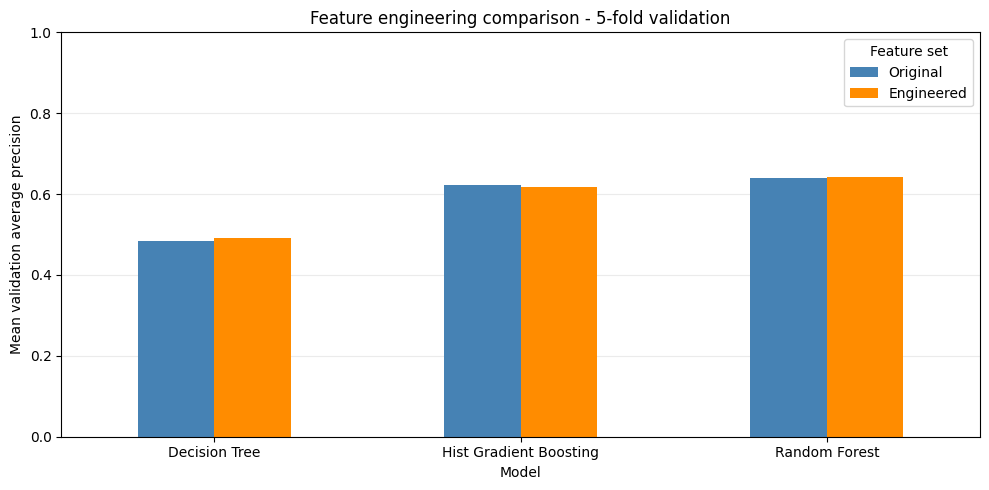

In [20]:
feature_comparison = cv_comparison.pivot(
    index="Model",
    columns="Features",
    values="CV AP"
)

feature_comparison["AP change"] = (
    feature_comparison["Engineered"]
    - feature_comparison["Original"]
)

display(feature_comparison.round(4))

ax = feature_comparison[
    ["Original", "Engineered"]
].plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "darkorange"],
    rot=0
)

ax.set_title("Feature engineering comparison - 5-fold validation")
ax.set_xlabel("Model")
ax.set_ylabel("Mean validation average precision")
ax.set_ylim(0, 1)
ax.legend(title="Feature set")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [21]:
for _, row in cv_comparison.iterrows():
    key = (row["Model"], row["Features"])
    search = searches[key]

    print("\nModel:", row["Model"])
    print("Features:", row["Features"])

    for parameter, value in search.best_params_.items():
        print(parameter.replace("model__", ""), ":", value)


Model: Random Forest
Features: Engineered
class_weight : balanced
max_depth : 10
min_samples_leaf : 2

Model: Random Forest
Features: Original
class_weight : balanced
max_depth : 10
min_samples_leaf : 2

Model: Hist Gradient Boosting
Features: Original
l2_regularization : 10
learning_rate : 0.03
max_leaf_nodes : 7

Model: Hist Gradient Boosting
Features: Engineered
l2_regularization : 10
learning_rate : 0.03
max_leaf_nodes : 15

Model: Decision Tree
Features: Engineered
max_depth : 4
min_samples_leaf : 10

Model: Decision Tree
Features: Original
max_depth : 4
min_samples_leaf : 10


جنگل تصادفی با ویژگی‌های جدید بهترین امتیاز اعتبارسنجی رو به دست آورد؛ میانگین دقت آن حدود ۰٫۶۴۲ و مساحت زیر منحنی مشخصه عملکرد حدود ۰٫۸۰۲ شد. ویژگی‌های جدید فقط حدود ۰٫۰۰۳۴ به معیار اصلی جنگل تصادفی اضافه کردن؛ بنابراین این بهبود کوچکه و نمی‌تونیم برتری قطعی اون‌ها رو ادعا کنیم. فاصله زیاد امتیاز آموزش و اعتبارسنجی هم نشانه بیش‌برازشه و تأکید می‌کنه که باید عملکرد مدل رو با داده‌های دیده‌نشده بسنجیم.

In [22]:
from sklearn.model_selection import cross_val_predict

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    auc,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

selected_keys = [
    ("Decision Tree", "Engineered"),
    ("Random Forest", "Engineered"),
    ("Hist Gradient Boosting", "Original")
]

final_key = ("Random Forest", "Engineered")

print("Selected final model:", final_key)

Selected final model: ('Random Forest', 'Engineered')


In [23]:
oof_probabilities = {}

for key in selected_keys:
    model_name, feature_name = key

    model = clone(searches[key].best_estimator_)
    training_data = feature_sets[feature_name]["X"]

    probabilities = cross_val_predict(
        model,
        training_data,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=2
    )[:, 1]

    oof_probabilities[key] = probabilities

    print("Finished:", model_name, "-", feature_name)

Finished: Decision Tree - Engineered
Finished: Random Forest - Engineered
Finished: Hist Gradient Boosting - Original


In [24]:
thresholds = np.append(
    np.round(np.arange(0, 1.001, 0.01), 2),
    1.01
)

threshold_tables = {}
selected_thresholds = {}
threshold_summary_rows = []

for key in selected_keys:
    probabilities = oof_probabilities[key]
    rows = []

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_train,
            predictions,
            labels=[0, 1]
        ).ravel()

        rows.append({
            "Threshold": threshold,
            "FP": fp,
            "FN": fn,
            "Cost": fp + 5 * fn,
            "Accuracy": accuracy_score(y_train, predictions),
            "Bad credit recall": recall_score(
                y_train, predictions, zero_division=0
            ),
            "Bad credit precision": precision_score(
                y_train, predictions, zero_division=0
            )
        })

    table = pd.DataFrame(rows)
    threshold_tables[key] = table

    best_row = table.sort_values(
        ["Cost", "FN", "Threshold"]
    ).iloc[0]

    selected_thresholds[key] = float(best_row["Threshold"])

    default_row = table.loc[
        table["Threshold"] == 0.50
    ].iloc[0]

    threshold_summary_rows.append({
        "Model": key[0],
        "Features": key[1],
        "Selected threshold": best_row["Threshold"],
        "OOF cost at 0.50": default_row["Cost"],
        "OOF tuned cost": best_row["Cost"],
        "OOF tuned recall": best_row["Bad credit recall"],
        "OOF tuned precision": best_row["Bad credit precision"]
    })

threshold_summary = pd.DataFrame(threshold_summary_rows)
display(threshold_summary.round(4))

,Model,Features,Selected threshold,OOF cost at 0.50,OOF tuned cost,OOF tuned recall,OOF tuned precision
0,Decision Tree,Engineered,0.15,803.0,450.0,0.8750,0.4118
1,Random Forest,Engineered,0.37,534.0,402.0,0.8667,0.4622
2,Hist Gradient Boosting,Original,0.12,779.0,420.0,0.9625,0.3812


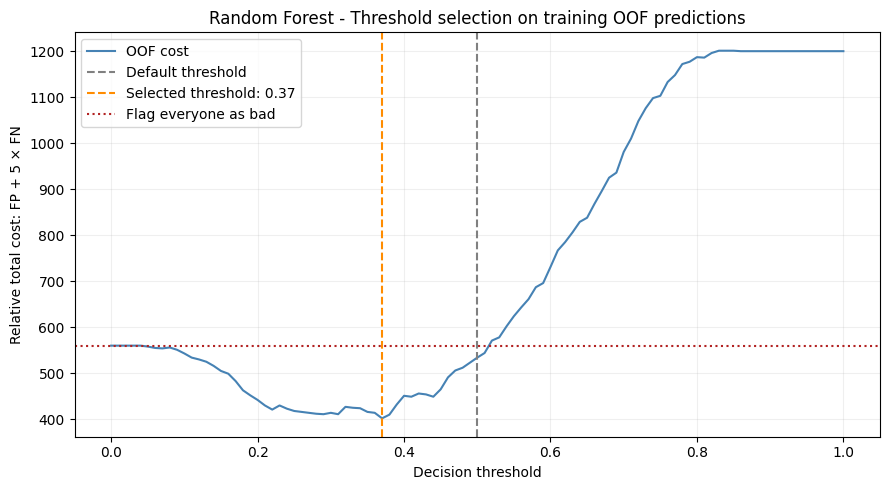

In [25]:
final_threshold = selected_thresholds[final_key]
final_threshold_table = threshold_tables[final_key]

plot_data = final_threshold_table[
    final_threshold_table["Threshold"] <= 1
]

plt.figure(figsize=(9, 5))

plt.plot(
    plot_data["Threshold"],
    plot_data["Cost"],
    color="steelblue",
    label="OOF cost"
)

plt.axvline(
    0.50,
    color="gray",
    linestyle="--",
    label="Default threshold"
)

plt.axvline(
    final_threshold,
    color="darkorange",
    linestyle="--",
    label=f"Selected threshold: {final_threshold:.2f}"
)

plt.axhline(
    (y_train == 0).sum(),
    color="firebrick",
    linestyle=":",
    label="Flag everyone as bad"
)

plt.title("Random Forest - Threshold selection on training OOF predictions")
plt.xlabel("Decision threshold")
plt.ylabel("Relative total cost: FP + 5 × FN")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [26]:
fitted_models = {}
test_probabilities = {}
test_predictions = {}

test_rows = []

for key in selected_keys:
    model_name, feature_name = key

    training_data = feature_sets[feature_name]["X"]

    if feature_name == "Engineered":
        testing_data = X_test_fe
    else:
        testing_data = X_test

    model = clone(searches[key].best_estimator_)
    model.fit(training_data, y_train)

    probabilities = model.predict_proba(testing_data)[:, 1]

    fitted_models[key] = model
    test_probabilities[key] = probabilities

    pr_precision, pr_recall, _ = precision_recall_curve(
        y_test, probabilities
    )

    roc_auc = roc_auc_score(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)
    pr_auc = auc(pr_recall, pr_precision)

    for policy, threshold in [
        ("Default", 0.50),
        ("Cost-tuned", selected_thresholds[key])
    ]:
        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test,
            predictions,
            labels=[0, 1]
        ).ravel()

        test_predictions[(key, policy)] = predictions

        test_rows.append({
            "Model": model_name,
            "Features": feature_name,
            "Policy": policy,
            "Threshold": threshold,
            "Test ROC-AUC": roc_auc,
            "Test AP": ap,
            "Test PR-AUC (trapezoidal)": pr_auc,
            "Test accuracy": accuracy_score(y_test, predictions),
            "Bad credit precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Bad credit recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "Bad credit F1": f1_score(
                y_test, predictions, zero_division=0
            ),
            "FP": fp,
            "FN": fn,
            "Total cost": fp + 5 * fn,
            "Cost per customer": (fp + 5 * fn) / len(y_test)
        })

test_comparison = pd.DataFrame(test_rows)
display(test_comparison.round(4))

,Model,Features,Policy,Threshold,Test ROC-AUC,Test AP,Test PR-AUC (trapezoidal),Test accuracy,Bad credit precision,Bad credit recall,Bad credit F1,FP,FN,Total cost,Cost per customer
0,Decision Tree,Engineered,Default,0.50,0.6942,0.4693,0.4910,0.710,0.5263,0.3333,0.4082,18,40,218,1.090
1,Decision Tree,Engineered,Cost-tuned,0.15,0.6942,0.4693,0.4910,0.570,0.3952,0.8167,0.5326,75,11,130,0.650
2,Random Forest,Engineered,Default,0.50,0.8155,0.6765,0.6731,0.755,0.5753,0.7000,0.6316,31,18,121,0.605
3,Random Forest,Engineered,Cost-tuned,0.37,0.8155,0.6765,0.6731,0.650,0.4569,0.8833,0.6023,63,7,98,0.490
4,Hist Gradient Boosting,Original,Default,0.50,0.7786,0.6390,0.6357,0.740,0.6000,0.4000,0.4800,16,36,196,0.980
5,Hist Gradient Boosting,Original,Cost-tuned,0.12,0.7786,0.6390,0.6357,0.505,0.3725,0.9500,0.5352,96,3,111,0.555


جنگل تصادفی روی داده آزمون، مساحت زیر منحنی مشخصه عملکرد حدود ۰٫۸۱۶ و مساحت زیر منحنی دقت–بازیابی حدود ۰٫۶۷۳ به دست آورد و از دو مدل مقایسه‌شده بهتر عمل کرد. با کاهش آستانه از ۰٫۵ به ۰٫۳۷، تعداد بدحساب‌های شناسایی‌شده از ۴۲ به ۵۳ نفر رسید؛ در مقابل، تعداد خوش‌حساب‌هایی که اشتباه پرریسک تشخیص داده شدن از ۳۱ به ۶۳ نفر افزایش پیدا کرد. به همین دلیل دقت از ۷۵٫۵ به ۶۵ درصد کاهش یافت، ولی هزینه نسبی خطاها از ۱۲۱ به ۹۸ رسید؛ یعنی حدود ۱۹ درصد کاهش هزینه، طبق نسبت هزینه تعیین‌شده در مستندات.

In [27]:
policy_rows = []

simple_predictions = {
    "Everyone good": np.zeros(len(y_test), dtype=int),
    "Everyone bad": np.ones(len(y_test), dtype=int),
    "Selected Random Forest": test_predictions[
        (final_key, "Cost-tuned")
    ]
}

for policy, predictions in simple_predictions.items():
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    policy_rows.append({
        "Policy": policy,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Bad credit recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "FP": fp,
        "FN": fn,
        "Total cost": fp + 5 * fn,
        "Cost per customer": (fp + 5 * fn) / len(y_test)
    })

policy_comparison = pd.DataFrame(policy_rows)
display(policy_comparison.round(4))

,Policy,Test accuracy,Bad credit recall,FP,FN,Total cost,Cost per customer
0,Everyone good,0.70,0.0000,0,60,300,1.50
1,Everyone bad,0.30,1.0000,140,0,140,0.70
2,Selected Random Forest,0.65,0.8833,63,7,98,0.49


هزینه مدل منتخب ۹۸ واحده؛ در حالی که سیاست «همه خوش‌حساب» ۳۰۰ واحد و سیاست «همه بدحساب» ۱۴۰ واحد هزینه داره. بنابراین مدل در این نمونه آزمون، نسبت به این دو سیاست به‌ترتیب حدود ۶۷٫۳ و ۳۰ درصد هزینه کمتری ایجاد کرده. این اعداد هزینه نسبی هستن، نه مبلغ واقعی پول، و نتیجه به نسبت هزینه پنج‌به‌یک و همین نمونه آزمون وابسته است.

Final model: Random Forest
Feature set: Engineered
Selected threshold: 0.37
              precision    recall  f1-score   support

 Good credit     0.9167    0.5500    0.6875       140
  Bad credit     0.4569    0.8833    0.6023        60

    accuracy                         0.6500       200
   macro avg     0.6868    0.7167    0.6449       200
weighted avg     0.7787    0.6500    0.6619       200



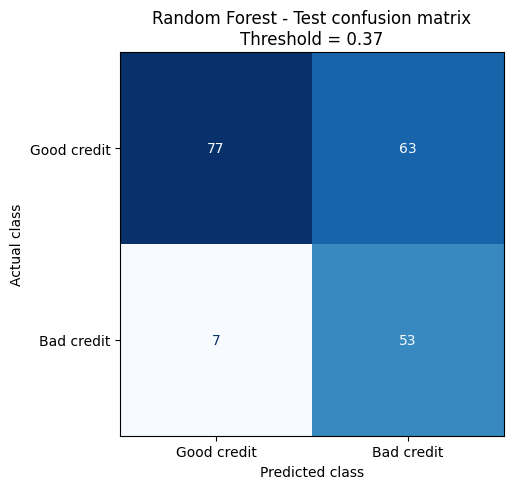

In [28]:
final_model = fitted_models[final_key]

final_probabilities = test_probabilities[final_key]

final_predictions = test_predictions[
    (final_key, "Cost-tuned")
]

print("Final model:", final_key[0])
print("Feature set:", final_key[1])
print("Selected threshold:", final_threshold)

print(
    classification_report(
        y_test,
        final_predictions,
        labels=[0, 1],
        target_names=["Good credit", "Bad credit"],
        digits=4,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    labels=[0, 1],
    display_labels=["Good credit", "Bad credit"],
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title(
    f"Random Forest - Test confusion matrix\n"
    f"Threshold = {final_threshold:.2f}"
)
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

plt.tight_layout()
plt.show()

مدل از ۶۰ مشتری بدحساب، ۵۳ نفر رو شناسایی کرده و ۷ نفر رو از دست داده؛ بنابراین بازیابی بدحساب‌ها حدود ۸۸٫۳ درصده. از طرف دیگه، ۶۳ مشتری خوش‌حساب هم اشتباه پرریسک تشخیص داده شدن و فقط حدود ۴۵٫۷ درصد هشدارهای مدل مربوط به بدحساب‌های واقعی بوده. پس این سیاست در شناسایی بدحساب‌ها موفق‌تره، ولی به قیمت افزایش هشدارهای اشتباه و احتمال از دست دادن مشتری خوب.

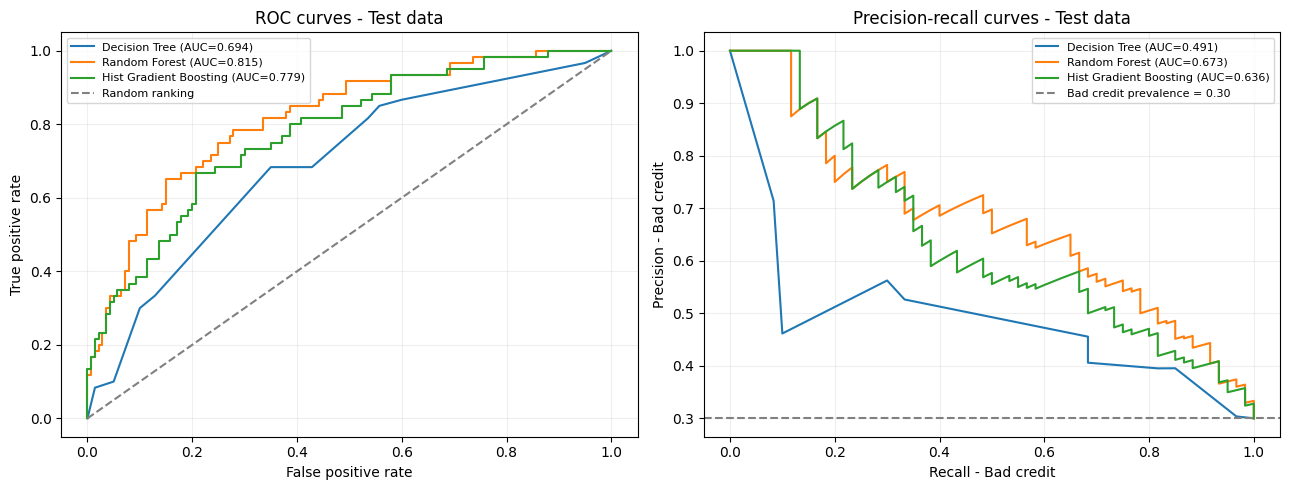

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for key in selected_keys:
    probabilities = test_probabilities[key]

    fpr, tpr, _ = roc_curve(y_test, probabilities)

    precision, recall, _ = precision_recall_curve(
        y_test, probabilities
    )

    roc_auc = roc_auc_score(y_test, probabilities)
    pr_auc = auc(recall, precision)

    axes[0].plot(
        fpr, tpr,
        label=f"{key[0]} (AUC={roc_auc:.3f})"
    )

    axes[1].plot(
        recall, precision,
        label=f"{key[0]} (AUC={pr_auc:.3f})"
    )

axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random ranking"
)

axes[1].axhline(
    y_test.mean(),
    linestyle="--",
    color="gray",
    label=f"Bad credit prevalence = {y_test.mean():.2f}"
)

axes[0].set_title("ROC curves - Test data")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")

axes[1].set_title("Precision-recall curves - Test data")
axes[1].set_xlabel("Recall - Bad credit")
axes[1].set_ylabel("Precision - Bad credit")

for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [41]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.51.0


In [42]:
fitted_preprocessor = final_model.named_steps["preprocessor"]
fitted_forest = final_model.named_steps["model"]

shap_feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

X_train_transformed = pd.DataFrame(
    fitted_preprocessor.transform(X_train_fe),
    columns=shap_feature_names,
    index=X_train_fe.index
)

X_test_transformed = pd.DataFrame(
    fitted_preprocessor.transform(X_test_fe),
    columns=shap_feature_names,
    index=X_test_fe.index
)

print("Training shape:", X_train_transformed.shape)
print("Test shape:", X_test_transformed.shape)

assert np.array_equal(fitted_forest.classes_, [0, 1])

np.testing.assert_allclose(
    fitted_forest.predict_proba(X_test_transformed.to_numpy())[:, 1],
    final_probabilities
)

Training shape: (800, 63)
Test shape: (200, 63)


In [43]:
background_data = X_train_transformed.sample(
    n=100,
    random_state=42
)

explainer = shap.TreeExplainer(
    fitted_forest,
    data=background_data,
    feature_perturbation="interventional",
    model_output="probability"
)

shap_all_classes = explainer(X_test_transformed)

print("SHAP output shape:", shap_all_classes.values.shape)

# Class 1 = bad credit
shap_bad = shap_all_classes[:, :, 1]

reconstructed_probabilities = (
    shap_bad.base_values + shap_bad.values.sum(axis=1)
)

max_difference = np.max(
    np.abs(reconstructed_probabilities - final_probabilities)
)

print("Maximum reconstruction difference:", max_difference)

np.testing.assert_allclose(
    reconstructed_probabilities,
    final_probabilities,
    atol=1e-5,
    rtol=1e-5
)

SHAP output shape: (200, 63, 2)
Maximum reconstruction difference: 6.2983219750734065e-09


,Feature,Mean absolute SHAP
0,categorical__CheckingAccount_A14,0.07428
1,numeric__Duration,0.03954
2,categorical__CheckingAccount_A11,0.03429
3,categorical__Savings_A61,0.02800
4,categorical__CreditHistory_A34,0.02403
5,numeric__CreditAmount,0.02081
6,numeric__MonthlyPrincipal,0.02059
7,categorical__Savings_A65,0.01305
8,categorical__OtherInstallmentPlans_A143,0.01277
9,categorical__Property_A121,0.01261


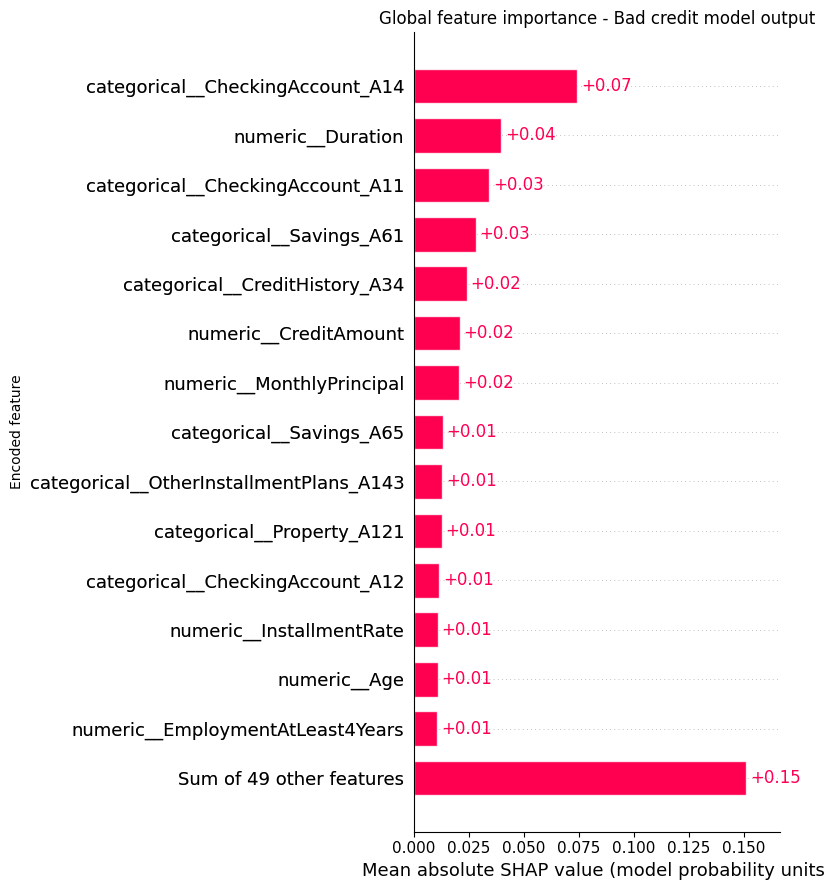

In [44]:
shap_importance = pd.DataFrame({
    "Feature": shap_feature_names,
    "Mean absolute SHAP": np.abs(shap_bad.values).mean(axis=0)
}).sort_values(
    "Mean absolute SHAP",
    ascending=False
).reset_index(drop=True)

display(shap_importance.head(20).round(5))

shap.plots.bar(
    shap_bad,
    max_display=15,
    show=False
)

plt.title("Global feature importance - Bad credit model output")
plt.xlabel("Mean absolute SHAP value (model probability units)")
plt.ylabel("Encoded feature")
plt.tight_layout()
plt.show()

در بین ستون‌های ورودی مدل، شاخص نداشتن حساب جاری بیشترین میانگین اندازه اثر رو داشته و بعد از اون، مدت وام و شاخص مانده منفی حساب قرار گرفتن. وضعیت پس‌انداز، سابقه اعتباری و مبلغ وام هم از عوامل مهم بودن. ویژگی جدید سهم ماهانه اصل وام هم در تصمیم‌های مدل نقش داشته، ولی مهم‌بودن آن در مدل به معنی ایجاد بهبود بزرگ در عملکرد نیست؛ مقایسه اعتبارسنجی نشان داد اضافه‌کردن دو ویژگی جدید فقط بهبود کوچکی ایجاد کرده.

این جدول اهمیت ستون‌های کدگذاری‌شده رو نشون می‌ده؛ بنابراین چند ستون مختلف ممکنه متعلق به یک ویژگی اصلی، مثل وضعیت حساب جاری، باشن. همچنین طول میله‌ها اندازه اثر رو نشان می‌ده و از روی این نمودار به‌تنهایی نمی‌شه جهت افزایش یا کاهش ریسک رو مشخص کرد.

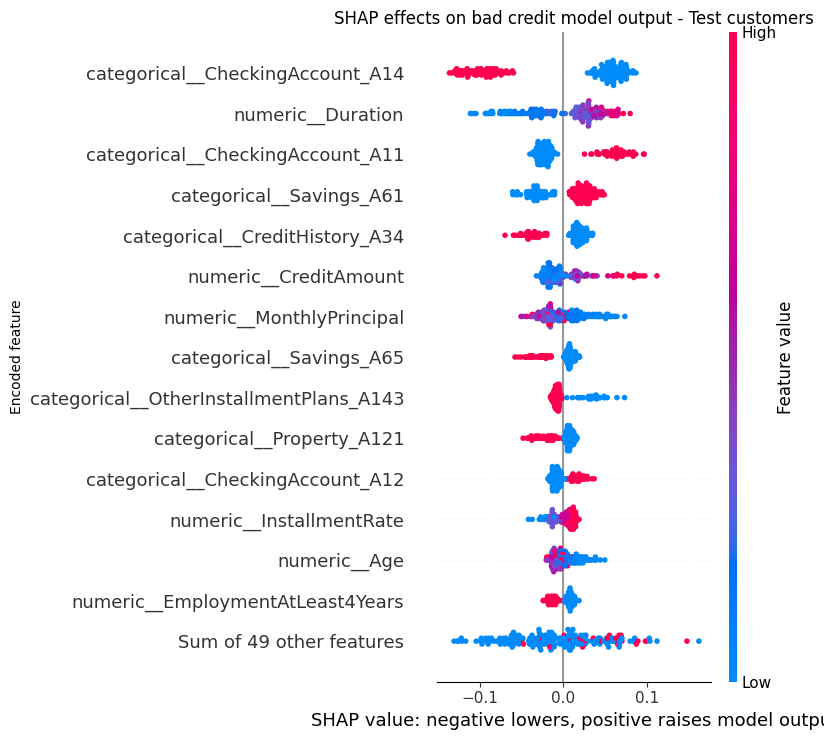

In [45]:
shap.plots.beeswarm(
    shap_bad,
    max_display=15,
    show=False
)

plt.title("SHAP effects on bad credit model output - Test customers")
plt.xlabel("SHAP value: negative lowers, positive raises model output")
plt.ylabel("Encoded feature")
plt.tight_layout()
plt.show()

در نمودار اثر ویژگی‌ها، مدت وام طولانی‌تر، مبلغ وام بالاتر، مانده منفی حساب و قرارگرفتن در گروه پس‌انداز کمتر از ۱۰۰ مارک، عموماً امتیاز بدحسابی مدل رو افزایش دادن. در مقابل، قرارگرفتن در گروه بدون حساب جاری و داشتن حداقل چهار سال سابقه اشتغال فعلی، بیشتر با کاهش امتیاز همراه بودن. این الگوها توضیح رفتار مدل روی همین داده هستن؛ مثلاً از کاهش امتیاز گروه بدون حساب جاری نمی‌شه نتیجه گرفت که بستن حساب بانکی باعث کاهش ریسک واقعی می‌شه.

In [46]:
case_positions = {}
case_rows = []

for predicted_class, case_name in [
    (0, "Lower-risk case"),
    (1, "Higher-risk case")
]:
    positions = np.flatnonzero(
        final_predictions == predicted_class
    )

    group_scores = final_probabilities[positions]
    median_score = np.median(group_scores)

    position = positions[
        np.argmin(np.abs(group_scores - median_score))
    ]

    case_positions[case_name] = int(position)

    case_rows.append({
        "Case": case_name,
        "Dataset row index": X_test_fe.index[position],
        "Model bad credit score": final_probabilities[position],
        "Threshold": final_threshold,
        "Predicted class": final_predictions[position],
        "Actual class": y_test.iloc[position]
    })

case_summary = pd.DataFrame(case_rows)
display(case_summary.round(4))

,Case,Dataset row index,Model bad credit score,Threshold,Predicted class,Actual class
0,Lower-risk case,657,0.2364,0.37,0,0
1,Higher-risk case,563,0.5341,0.37,1,1



Case: Lower-risk case
Dataset row index: 657
Actual class: 0
Predicted class: 0
Model bad credit score: 0.2364


,Customer value
CheckingAccount,A14
Duration,48
CreditHistory,A32
Purpose,A43
CreditAmount,10222
Savings,A65
Employment,A74
InstallmentRate,4
PersonalStatusSex,A93
OtherDebtors,A101


,Feature,Encoded value,SHAP effect,Absolute effect
0,categorical__CheckingAccount_A14,1.00000,-0.08729,0.08729
1,numeric__CreditAmount,10222.00000,0.06081,0.06081
2,numeric__Duration,48.00000,0.04079,0.04079
3,categorical__Savings_A65,1.00000,-0.03896,0.03896
4,categorical__OtherInstallmentPlans_A143,0.00000,0.03781,0.03781
5,categorical__Savings_A61,0.00000,-0.03474,0.03474
6,categorical__CheckingAccount_A11,0.00000,-0.02955,0.02955
7,numeric__EmploymentAtLeast4Years,1.00000,-0.02403,0.02403
8,numeric__MonthlyPrincipal,212.95833,-0.01625,0.01625
9,categorical__Employment_A74,1.00000,-0.01564,0.01564


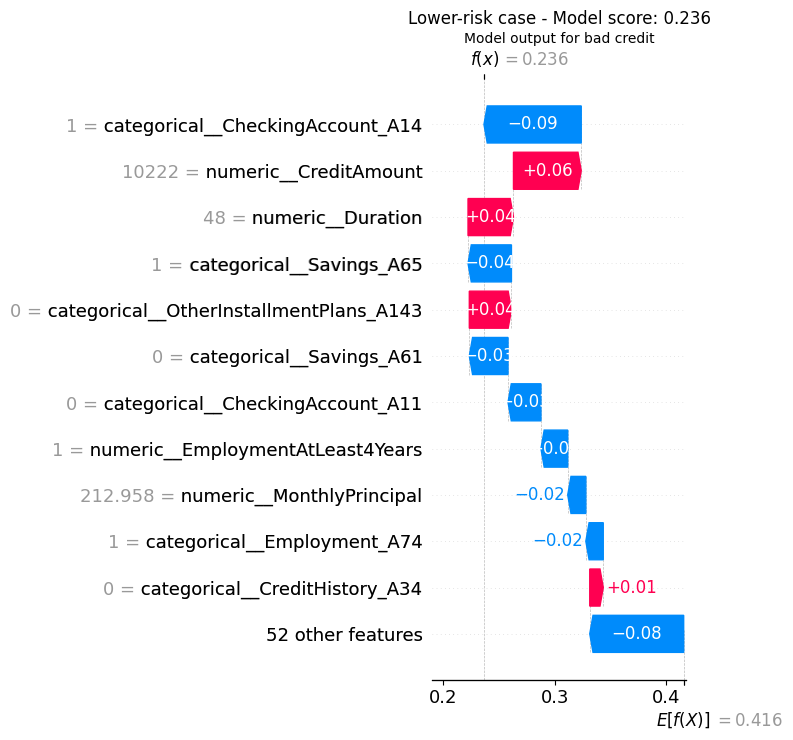


Case: Higher-risk case
Dataset row index: 563
Actual class: 1
Predicted class: 1
Model bad credit score: 0.5341


,Customer value
CheckingAccount,A12
Duration,36
CreditHistory,A32
Purpose,A40
CreditAmount,12389
Savings,A65
Employment,A73
InstallmentRate,1
PersonalStatusSex,A93
OtherDebtors,A101


,Feature,Encoded value,SHAP effect,Absolute effect
0,numeric__CreditAmount,12389.0,0.07942,0.07942
1,categorical__Savings_A65,1.0,-0.05762,0.05762
2,categorical__CheckingAccount_A14,0.0,0.05311,0.05311
3,categorical__Savings_A61,0.0,-0.03836,0.03836
4,categorical__Property_A124,1.0,0.03561,0.03561
5,numeric__Duration,36.0,0.03470,0.03470
6,categorical__CheckingAccount_A11,0.0,-0.01976,0.01976
7,categorical__Housing_A152,0.0,0.01728,0.01728
8,categorical__CheckingAccount_A12,1.0,0.01692,0.01692
9,numeric__InstallmentRate,1.0,-0.01669,0.01669


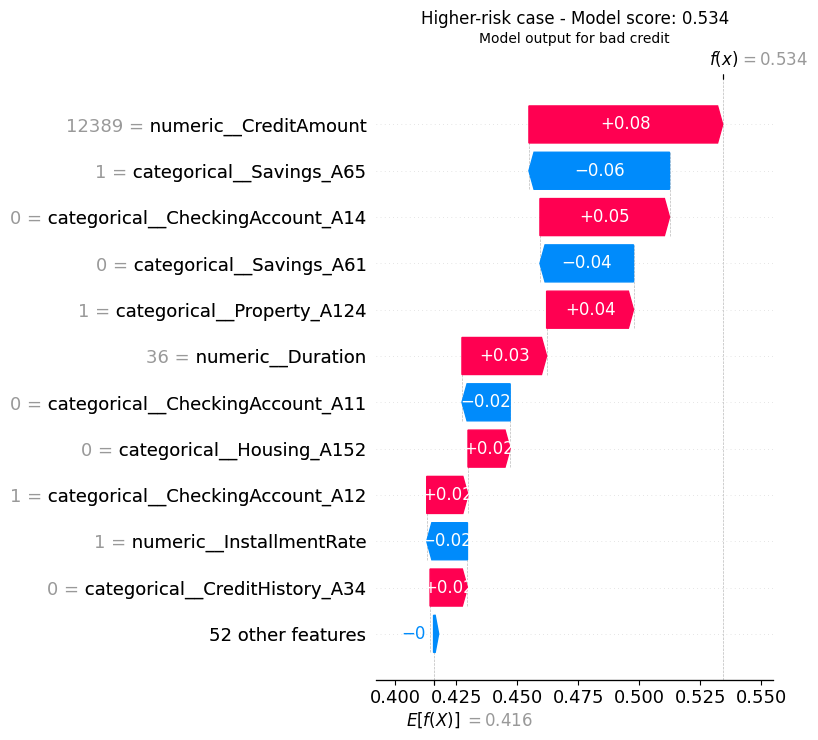

In [47]:
local_explanations = {}

for case_name, position in case_positions.items():
    print("\nCase:", case_name)
    print("Dataset row index:", X_test_fe.index[position])
    print("Actual class:", y_test.iloc[position])
    print("Predicted class:", final_predictions[position])
    print(
        "Model bad credit score:",
        round(final_probabilities[position], 4)
    )

    # Original and engineered customer information
    display(
        X_test_fe.iloc[position]
        .rename("Customer value")
        .to_frame()
    )

    local_table = pd.DataFrame({
        "Feature": shap_feature_names,
        "Encoded value": X_test_transformed.iloc[position].to_numpy(),
        "SHAP effect": shap_bad.values[position]
    })

    local_table["Absolute effect"] = (
        local_table["SHAP effect"].abs()
    )

    local_table = local_table.sort_values(
        "Absolute effect",
        ascending=False
    ).reset_index(drop=True)

    local_explanations[case_name] = local_table

    display(local_table.head(10).round(5))

    shap.plots.waterfall(
        shap_bad[position],
        max_display=12,
        show=False
    )

    plt.title(
        f"{case_name} - Model score: "
        f"{final_probabilities[position]:.3f}"
    )
    plt.xlabel("Model output for bad credit")
    plt.tight_layout()
    plt.show()

برای مشتری ردیف ۶۵۷، امتیاز مدل حدود ۰٫۲۳۶ شد که از آستانه ۰٫۳۷ پایین‌تره؛ بنابراین مدل او رو خوش‌حساب پیش‌بینی کرد و برچسب واقعی هم خوش‌حساب بود. مبلغ وام ۱۰۲۲۲ مارک و مدت بازپرداخت ۴۸ ماه، امتیاز بدحسابی رو به‌ترتیب حدود ۶٫۰۸ و ۴٫۰۸ واحد درصد افزایش دادن. با این حال، سهم کاهشی شاخص نداشتن حساب جاری، برخی شاخص‌های پس‌انداز و سابقه اشتغال باعث شد مجموع اثرها امتیاز رو از مقدار پایه حدود ۰٫۴۱۶ پایین‌تر بیاره.

پس مدل فقط بر اساس مبلغ یا مدت وام تصمیم نگرفته؛ ترکیب ویژگی‌ها باعث شده این مشتری با وجود وام بزرگ و بلندمدت، در گروه کم‌ریسک قرار بگیره.

برای مشتری ردیف ۵۶۳، امتیاز مدل حدود ۰٫۵۳۴ شد که بالاتر از آستانه ۰٫۳۷ است؛ بنابراین مدل او رو بدحساب پیش‌بینی کرد و برچسب واقعی هم بدحساب بود. مبلغ وام ۱۲۳۸۹ مارک، به‌تنهایی سهم افزایشی حدود ۷٫۹۴ واحد درصد داشت. مدت ۳۶ماهه وام و قرارگرفتن در دسته «دارایی نامشخص یا نداشتن دارایی» هم امتیاز رو افزایش دادن؛ در مقابل، بعضی شاخص‌های پس‌انداز اثر کاهشی داشتن، اما برای پایین‌آوردن امتیاز از آستانه کافی نبودن.

این دو مشتری بر اساس نزدیکی امتیازشان به میانه گروه پیش‌بینی‌شده انتخاب شدن، نه بر اساس درست‌بودن پیش‌بینی. درست‌بودن هر دو مثال هم به معنی بی‌خطابودن مدل نیست؛ خطاهای مدل در ارزیابی کل مجموعه آزمون گزارش شده‌اند.

-------------------

مدل و توضیح‌های آن ارتباط‌های موجود در داده رو نشان می‌دن، اما از این تحلیل نمی‌تونیم مشخص کنیم کدام ویژگی قطعاً علت نکول است. برای مثال، مبلغ وام و مدت بازپرداخت می‌تونن از مسیر تعهدات مالی با توان پرداخت ارتباط داشته باشن؛ ولی درآمد، هزینه‌های زندگی، نرخ سود و شرایط انتخاب مشتری‌ها هم ممکنه روی این ارتباط اثر بذارن. چون همه این اطلاعات رو نداریم، اثر علّی افزایش مبلغ یا تغییر مدت وام رو از نتایج فعلی اثبات نمی‌کنیم.

ویژگی‌هایی مثل سن، سابقه اشتغال و وضعیت حساب جاری ممکنه نشانه شرایط دیگری مانند ثبات درآمد، سابقه رابطه با بانک یا نوع مشتری باشن. برای مثال، پایین‌تر بودن امتیاز مدل برای گروه بدون حساب جاری به معنی مفیدبودن بستن حساب نیست. همین‌طور اثر کاهشی دسته «پس‌انداز نامشخص یا نداشتن حساب پس‌انداز» نباید به توصیه پنهان‌کردن اطلاعات تبدیل بشه.

برای سیاست‌گذاری، مبلغ وام، برنامه بازپرداخت و حمایت آموزشی می‌تونن گزینه‌های قابل‌بررسی باشن؛ اما قبل از اجرای گسترده باید اثر واقعی آن‌ها با اطلاعات تکمیلی و یک مطالعه مناسب بررسی بشه. مثلاً کوتاه‌کردن مدت وام ممکنه برخلاف انتظار، فشار پرداخت ماهانه رو بیشتر کنه. بنابراین تغییر یک ویژگی برای پایین‌آوردن امتیاز مدل، لزوماً ریسک واقعی رو کاهش نمی‌ده و اتکای صرف به همبستگی می‌تونه هم زیان اعتباری و هم رد اشتباه مشتری‌های خوب رو افزایش بده.

--------------------

این پروژه یک مدل اولیه روی ۱۰۰۰ رکورد تاریخی است و ارزیابی نهایی فقط روی ۲۰۰ مشتری انجام شده؛ بنابراین نتیجه برای استفاده مستقیم در شرایط امروز کافی نیست. اطلاعات مهمی مثل درآمد واقعی و نرخ سود هم موجود نیست و خروجی احتمالی مدل کالیبره نشده. علاوه بر این، سهم ویژگی‌های مرتبط به هم در توضیح‌پذیری به داده مرجع و روش محاسبه وابسته است.

با آستانه انتخاب‌شده، ۶۳ مشتری خوش‌حساب اشتباه پرریسک تشخیص داده شدن. بنابراین استفاده از مدل برای اولویت‌بندی بررسی کارشناسی، پیشنهاد قابل‌بررسی‌تری از رد خودکار همه هشدارهاست؛ البته اثر و هزینه بررسی کارشناسی در این پروژه اندازه‌گیری نشده. پیش از کاربرد واقعی، ارزیابی روی داده جدید، بررسی پایداری، کالیبراسیون و بررسی تفاوت خطاها بین گروه‌های مشتریان لازم است.

----------

پرامپت پیشنهادی

نقش تو تهیه پیش‌نویس توضیح برای مشتری در یک مثال آموزشی اعتبارسنجی است. فرض کن طبق سیاست این مثال، درخواست مشتری ردیف ۵۶۳ تأیید نشده است.

اطلاعات موجود:
- مبلغ وام: ۱۲۳۸۹ مارک.
- مدت وام: ۳۶ ماه.
- وضعیت حساب جاری: مانده بین صفر و کمتر از ۲۰۰ مارک.
- وضعیت دارایی: «نامشخص یا نداشتن دارایی»؛ مشخص نیست کدام حالت برقرار است.
- امتیاز مدل: ۰٫۵۳۴؛ آستانه تصمیم: ۰٫۳۷.
- سهم افزایشی مبلغ وام در خروجی مدل: حدود ۰٫۰۷۹۴.
- سهم افزایشی مدت وام: حدود ۰٫۰۳۴۷.
- سهم افزایشی شاخص وضعیت دارایی: حدود ۰٫۰۳۵۶.
یک متن کوتاه و محترمانه برای مشتری بنویس. از اصطلاحات فنی و معرفی مشتری به‌عنوان «بدحساب قطعی» خودداری کن. توضیح بده مبلغ و مدت درخواست و وضعیت ثبت‌شده دارایی‌ها در ارزیابی مؤثر بودن، اما این‌ها علت قطعی نکول نیستن. درباره درآمد، بدهی معوق یا دارایی واقعی مشتری چیزی اختراع نکن.

پیشنهادهای عملی رو به روشن‌کردن اطلاعات، بررسی توان پرداخت و گفت‌وگو درباره مبلغ و برنامه بازپرداخت متناسب محدود کن. تغییر شرایط وام رو تضمین‌کننده تأیید درخواست معرفی نکن. این متن پیش‌نویس آموزشی است و باید پیش از استفاده واقعی توسط کارشناس بررسی شود.

نمونه پاسخ مدل زبانی

مشتری گرامی، درخواست شما در این ارزیابی اولیه تأیید نشده است. مبلغ درخواستی، دوره بازپرداخت و وضعیت ثبت‌شده دارایی‌ها از عوامل مؤثر در این نتیجه بوده‌اند. این تصمیم به معنی قطعی‌بودن ناتوانی شما در بازپرداخت نیست.

از آنجا که وضعیت دارایی در پرونده به‌صورت «نامشخص یا بدون دارایی» ثبت شده، در صورت ناقص یا نادرست‌بودن اطلاعات، می‌توانید برای اصلاح آن اقدام کنید. همچنین پیشنهاد می‌کنیم همراه کارشناس، مبلغ درخواست و برنامه بازپرداخت را با درآمد و هزینه‌های واقعی خود بررسی کنید؛ کاهش مبلغ یا تغییر برنامه پرداخت فقط در صورتی مناسب است که با توان مالی شما سازگار باشد.

تکمیل اطلاعات می‌تواند به بررسی دقیق‌تر کمک کند، اما تأیید درخواست بعدی را تضمین نمی‌کند.